# 5. Pipeline final

**Objetivo:** empaquetar todo el proceso (limpieza → ingeniería de variables → modelo) en **un solo objeto** de scikit-learn que:
- recibe los datos **originales** del Titanic,
- aprende imputaciones solo con datos de entrenamiento (sin fuga de información),
- se puede guardar en disco y usar en una aplicación (`app.py`).

El mejor modelo se toma de `results/mejor_modelo.txt` (cuaderno 4) y se ajustan sus hiperparámetros con `GridSearchCV`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix, RocCurveDisplay
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from titanic_features import TitanicFeatures, NUM_FEATURES, CAT_FEATURES

SEED = 42
os.makedirs("models", exist_ok=True)

## 5.1 Datos originales

In [2]:
raw = pd.read_csv("data/titanic.csv")
X = raw.drop(columns=["Survived"])
y = raw["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

mejor = open("results/mejor_modelo.txt", encoding="utf-8").read().strip()
print("Modelo elegido en el cuaderno 4:", mejor)

Modelo elegido en el cuaderno 4: Gradient Boosting


## 5.2 Modelo y rejilla de hiperparámetros

In [3]:
catalogo = {
    "Regresión Logística": (LogisticRegression(max_iter=2000, random_state=SEED),
                            {"model__C": [0.01, 0.1, 0.5, 1, 5, 10]}),
    "SVC": (SVC(probability=True, random_state=SEED),
            {"model__C": [0.5, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.05]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10]}),
    "KNeighbors": (KNeighborsClassifier(),
                   {"model__n_neighbors": [5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {"model__n_estimators": [300, 500], "model__max_depth": [5, 7, 9], "model__min_samples_leaf": [1, 3]}),
    "AdaBoost": (AdaBoostClassifier(random_state=SEED),
                 {"model__n_estimators": [100, 200, 400], "model__learning_rate": [0.1, 0.5, 1.0]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"model__n_estimators": [100, 200, 300], "model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.05, 0.1]}),
    "CatBoost": (CatBoostClassifier(verbose=0, random_seed=SEED, allow_writing_files=False),
                 {"model__iterations": [300, 500], "model__depth": [4, 5, 6], "model__learning_rate": [0.03, 0.05]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=SEED, subsample=0.9, colsample_bytree=0.9),
                {"model__n_estimators": [200, 300, 500], "model__max_depth": [3, 4, 5], "model__learning_rate": [0.03, 0.05]}),
    "LightGBM": (LGBMClassifier(random_state=SEED, verbose=-1),
                 {"model__n_estimators": [200, 300, 500], "model__max_depth": [3, 4, 5], "model__learning_rate": [0.03, 0.05], "model__num_leaves": [7, 15]}),
    "GaussianNB": (GaussianNB(), {"model__var_smoothing": [1e-9, 1e-8, 1e-7]}),
}
estimador, rejilla = catalogo[mejor]
print(estimador)
print(rejilla)

GradientBoostingClassifier(random_state=42)
{'model__n_estimators': [100, 200, 300], 'model__max_depth': [2, 3, 4], 'model__learning_rate': [0.03, 0.05, 0.1]}


## 5.3 Construcción del pipeline

In [4]:
preprocesamiento = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
])

pipeline = Pipeline([
    ("features", TitanicFeatures()),   # limpieza + variables nuevas (cuadernos 1 y 3)
    ("prep", preprocesamiento),        # escalado + one-hot
    ("model", estimador),              # mejor modelo (cuaderno 4)
])
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,split_rare,False
,fare_zero,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_

## 5.4 Ajuste de hiperparámetros (GridSearchCV, 5 pliegues, AUC-ROC)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
busqueda = GridSearchCV(pipeline, rejilla, cv=cv, scoring="roc_auc", n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("AUC-ROC en validación cruzada:", round(busqueda.best_score_, 4))
modelo = busqueda.best_estimator_

Mejores hiperparámetros: {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200}
AUC-ROC en validación cruzada: 0.895


## 5.5 Evaluación final en prueba

In [6]:
pred = modelo.predict(X_test)
proba = modelo.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

metricas_finales = pd.Series({
    "Exactitud": accuracy_score(y_test, pred),
    "Precisión": precision_score(y_test, pred),
    "Sensibilidad": recall_score(y_test, pred),
    "Especificidad": tn / (tn + fp),
    "AUC-ROC": roc_auc_score(y_test, proba),
}).round(4)
metricas_finales

Exactitud        0.8045
Precisión        0.7833
Sensibilidad     0.6812
Especificidad    0.8818
AUC-ROC          0.8495
dtype: float64

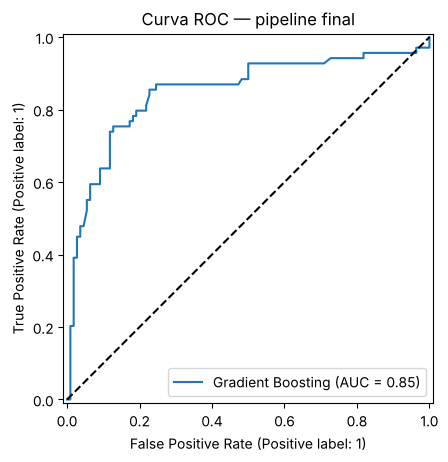

In [7]:
RocCurveDisplay.from_predictions(y_test, proba, name=mejor)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Curva ROC — pipeline final")
plt.show()

## 5.6 Interpretación sobre las variables originales

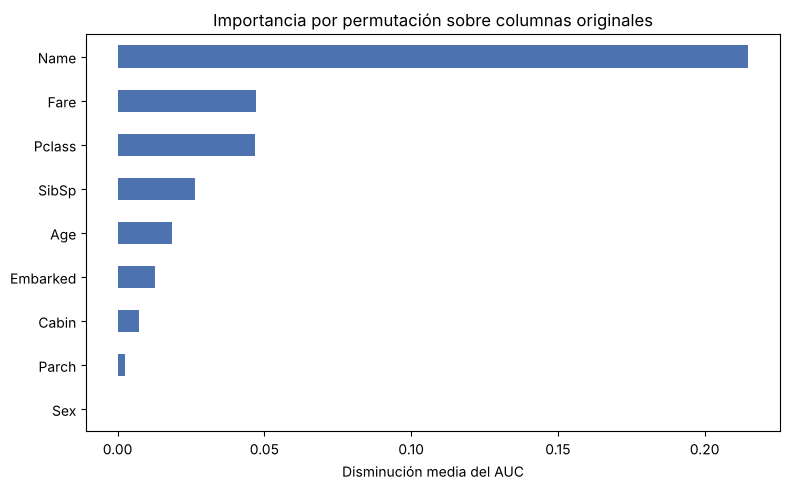

Name        0.2149
Fare        0.0473
Pclass      0.0469
SibSp       0.0265
Age         0.0184
Embarked    0.0126
Cabin       0.0073
Parch       0.0024
Sex        -0.0000
dtype: float64

In [8]:
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Name", "Cabin"]
perm = permutation_importance(modelo, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).loc[cols].sort_values()
imp.plot.barh(figsize=(8, 5), color="#4c72b0")
plt.title("Importancia por permutación sobre columnas originales")
plt.xlabel("Disminución media del AUC")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4)

Al permutar columnas **originales** se ve el efecto completo de cada dato capturado:
- **`Name`** es la más importante porque de ahí sale el **título** (Mr, Mrs, Miss, Master), que resume sexo, edad y estado civil.
- **`Fare`** y **`Pclass`** reflejan el nivel socioeconómico.
- **`Sex`** aparece con importancia ~0, **no porque no importe**, sino porque el título ya contiene esa información: si se desordena `Sex`, el modelo sigue sabiendo el sexo por el título. Es un ejemplo de **variables redundantes**: la importancia por permutación se reparte entre ellas.

**Métricas finales en prueba (Gradient Boosting ajustado):** exactitud 80.4 %, precisión 0.78, sensibilidad 0.68, especificidad 0.88, AUC-ROC 0.850 (AUC en validación cruzada 0.895).

## 5.7 Entrenamiento con todos los datos y guardado

In [9]:
modelo_produccion = busqueda.best_estimator_.fit(X, y)
joblib.dump(modelo_produccion, "models/titanic_pipeline.joblib")
print("Guardado models/titanic_pipeline.joblib")

Guardado models/titanic_pipeline.joblib


## 5.8 Prueba de uso: pasajeros nuevos

In [10]:
cargado = joblib.load("models/titanic_pipeline.joblib")

nuevos = pd.DataFrame([
    {"PassengerId": 9001, "Pclass": 1, "Name": "Doe, Mrs. Jane", "Sex": "female", "Age": 30,
     "SibSp": 1, "Parch": 0, "Ticket": "X1", "Fare": 80.0, "Cabin": "C85", "Embarked": "C"},
    {"PassengerId": 9002, "Pclass": 3, "Name": "Doe, Mr. John", "Sex": "male", "Age": 28,
     "SibSp": 0, "Parch": 0, "Ticket": "X2", "Fare": 7.9, "Cabin": None, "Embarked": "S"},
    {"PassengerId": 9003, "Pclass": 2, "Name": "Doe, Master. Tom", "Sex": "male", "Age": 6,
     "SibSp": 1, "Parch": 2, "Ticket": "X3", "Fare": 29.0, "Cabin": None, "Embarked": "S"},
])
nuevos["Prob_sobrevivir"] = cargado.predict_proba(nuevos)[:, 1].round(3)
nuevos["Prediccion"] = np.where(nuevos["Prob_sobrevivir"] >= 0.5, "Sobrevive", "No sobrevive")
nuevos[["Name", "Pclass", "Sex", "Age", "Fare", "Prob_sobrevivir", "Prediccion"]]

,Name,Pclass,Sex,Age,Fare,Prob_sobrevivir,Prediccion
0,"Doe, Mrs. Jane",1,female,30,80.0,0.956,Sobrevive
1,"Doe, Mr. John",3,male,28,7.9,0.082,No sobrevive
2,"Doe, Master. Tom",2,male,6,29.0,0.927,Sobrevive


## Resumen
- Un solo objeto (`models/titanic_pipeline.joblib`) hace todo: limpieza, variables nuevas, escalado, codificación y predicción.
- Las imputaciones se aprenden solo con el conjunto de entrenamiento, eliminando la fuga de información que tendría limpiar todo el dataset antes de dividirlo.
- Se usa en `app.py`: `python app.py` y abrir http://127.0.0.1:5000